# TFG — Comparación de métodos para valorar una **call americana con dividendos** bajo **volatilidad con cambio de régimen**

Este notebook está pensado para que el tribunal pueda **ver, de forma directa y comparable**, qué aporta cada enfoque:

- **Árbol binomial CRR** (benchmark en el caso de volatilidad constante)
- **Monte Carlo + Longstaff–Schwartz (LSMC)**
- **Monte Carlo + LSMC + Importance Sampling (IS)**

La idea es que las salidas sean **tablas y gráficos “de decisión”**: precio, error estándar, varianza, tiempo y una medida de eficiencia.

## Cómo está organizado (coherente con el texto)

- **Sección 3 (Métodos)**: aquí tienes las funciones de CRR, LSMC e IS.
- **Sección 4 (Implementación y resultados)**: aquí se ejecutan escenarios comparables y se generan **tablas** y **figuras**.

> Nota: el objetivo no es “enseñar Python”, sino dejar una implementación reproducible y, sobre todo, una **comparación limpia**.

In [1]:
# 1) Imports y configuración
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from dataclasses import dataclass

np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.precision", 6)
pd.set_option("display.max_columns", 50)

def set_seed(seed: int) -> np.random.Generator:
    return np.random.default_rng(int(seed))

## 1. Modelo, parámetros y simulación

In [2]:
# 2) Parámetros del modelo y utilidades

@dataclass(frozen=True)
class RegimeParams:
    sigmas: np.ndarray   # (R,) volatilidades por régimen
    P: np.ndarray        # (R,R) matriz de transición (filas suman 1)

@dataclass(frozen=True)
class MarketParams:
    r: float             # tipo libre de riesgo (continuo)
    q: float             # dividend yield continuo

def validate_params(regime: RegimeParams, market: MarketParams):
    sigmas = np.asarray(regime.sigmas, dtype=float)
    P = np.asarray(regime.P, dtype=float)

    if sigmas.ndim != 1:
        raise ValueError("sigmas debe ser un vector 1D (R,).")
    if np.any(sigmas <= 0):
        raise ValueError("todas las sigmas deben ser > 0.")
    R = sigmas.shape[0]

    if P.shape != (R, R):
        raise ValueError(f"P debe tener forma {(R,R)}.")
    if np.any(P < 0):
        raise ValueError("P no puede tener probabilidades negativas.")
    row_sums = P.sum(axis=1)
    if not np.allclose(row_sums, 1.0):
        raise ValueError("cada fila de P debe sumar 1.")
    if market.r < 0:
        raise ValueError("r debe ser >= 0 (en este trabajo lo tratamos así).")

def payoff_call(S: np.ndarray, K: float) -> np.ndarray:
    return np.maximum(S - float(K), 0.0)

def discount_factor(r: float, t: float) -> float:
    return float(np.exp(-r * t))

In [3]:
# 3) Simulación del estado (S_t, X_t) con cambio de régimen

def simulate_markov_regimes(P: np.ndarray, n_steps: int, n_paths: int, x0: int, rng: np.random.Generator):
    """Simula regímenes X_n en {0,...,R-1} con transición P (discreta por pasos)."""
    P = np.asarray(P, dtype=float)
    R = P.shape[0]
    X = np.empty((n_steps + 1, n_paths), dtype=np.int32)
    X[0, :] = int(x0)

    # distribución acumulada por fila para muestreo rápido
    cdf = np.cumsum(P, axis=1)

    u = rng.random((n_steps, n_paths))
    for t in range(n_steps):
        prev = X[t, :]
        # para cada régimen, decide el siguiente comparando con su CDF
        next_state = np.empty(n_paths, dtype=np.int32)
        for rg in range(R):
            idx = (prev == rg)
            if not np.any(idx):
                continue
            # busca primera posición donde cdf[rg, j] >= u
            next_state[idx] = np.searchsorted(cdf[rg], u[t, idx], side="right")
        X[t+1, :] = next_state

    return X

def simulate_price_paths_regime_switching(
    S0: float, K: float, T: float,
    n_steps: int, n_paths: int,
    regime: RegimeParams, market: MarketParams,
    x0: int = 0, seed: int = 123
):
    """Simula (S, X) bajo medida neutral al riesgo con dividendos y volatilidad dependiente de régimen."""
    validate_params(regime, market)
    rng = set_seed(seed)
    dt = float(T) / int(n_steps)

    # regímenes y shocks
    X = simulate_markov_regimes(regime.P, n_steps=n_steps, n_paths=n_paths, x0=x0, rng=rng)
    Z = rng.normal(loc=0.0, scale=1.0, size=(n_steps, n_paths))

    S = np.empty((n_steps + 1, n_paths), dtype=np.float64)
    S[0, :] = float(S0)

    for t in range(n_steps):
        sigma_t = regime.sigmas[X[t, :]]
        drift = (market.r - market.q - 0.5 * sigma_t**2) * dt
        diff  = sigma_t * np.sqrt(dt) * Z[t, :]
        S[t + 1, :] = S[t, :] * np.exp(drift + diff)

    Phi = payoff_call(S, K)
    return S, X, Phi, dt

## 2. Métodos de valoración (CRR, LSMC, LSMC+IS)

In [4]:
# 4) Árbol binomial CRR para call americana con dividendos (benchmark cuando sigma es constante)

def crr_american_call(S0: float, K: float, r: float, q: float, sigma: float, T: float, N: int):
    """
    CRR recombinante con dividend yield continuo (q) y ejercicio americano.
    Se usa como benchmark SOLO cuando la volatilidad es constante.
    """
    dt = float(T) / int(N)
    u = np.exp(float(sigma) * np.sqrt(dt))
    d = 1.0 / u
    disc = np.exp(-float(r) * dt)
    p = (np.exp((float(r) - float(q)) * dt) - d) / (u - d)
    if not (0.0 < p < 1.0):
        raise ValueError("Probabilidad neutral al riesgo fuera de (0,1). Ajusta N o parámetros.")

    # precios en vencimiento
    j = np.arange(N + 1)
    S_T = float(S0) * (u**j) * (d**(N - j))
    V = np.maximum(S_T - float(K), 0.0)

    # backward induction con ejercicio anticipado
    for n in range(N - 1, -1, -1):
        V = disc * (p * V[1:] + (1.0 - p) * V[:-1])
        j = np.arange(n + 1)
        S_n = float(S0) * (u**j) * (d**(n - j))
        V = np.maximum(V, np.maximum(S_n - float(K), 0.0))
    return float(V[0])

In [5]:
# 5) LSMC (Longstaff–Schwartz) — regresión separada por régimen

def state_transform(S: np.ndarray, K: float) -> np.ndarray:
    """Escalado simple para estabilidad numérica: x = S/K (magnitud ~ 1 cerca del strike)."""
    return np.asarray(S, dtype=float).reshape(-1) / float(K)

def basis_poly(x: np.ndarray, degree: int = 2) -> np.ndarray:
    """Base polinómica: [1, x, x^2, ...]."""
    x = np.asarray(x, dtype=float).reshape(-1)
    return np.vstack([x**k for k in range(degree + 1)]).T

def basis_laguerre(x: np.ndarray, degree: int = 2) -> np.ndarray:
    """
    Laguerre (no normalizados) evaluados en x (normalmente x=S/K).
    Para degree 2: [1, 1-x, 1-2x+x^2/2]
    """
    x = np.asarray(x, dtype=float).reshape(-1)
    L0 = np.ones_like(x)
    if degree == 0:
        return L0[:, None]
    L1 = 1.0 - x
    if degree == 1:
        return np.column_stack([L0, L1])
    L2 = 1.0 - 2.0*x + 0.5*x**2
    if degree == 2:
        return np.column_stack([L0, L1, L2])
    L3 = 1.0 - 3.0*x + 1.5*x**2 - (1.0/6.0)*x**3
    if degree == 3:
        return np.column_stack([L0, L1, L2, L3])
    raise ValueError("degree soportado: 0..3")

def ols_fit(A: np.ndarray, y: np.ndarray) -> np.ndarray:
    """OLS por mínimos cuadrados (np.linalg.lstsq)."""
    beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    return beta

def lsmc_train_policy(
    S: np.ndarray, X: np.ndarray,
    K: float, r: float, dt: float,
    basis: str = "laguerre",
    degree: int = 2,
    min_itm: int = 50,
):
    """
    Entrena la policy LSMC y devuelve:
      - tau: (M,) paso de ejercicio
      - payoff_tau: (M,) payoff en tau
      - betas: lista longitud N+1, cada entrada dict {reg: beta} (solo para 1..N-1)

    La regresión se hace solo sobre trayectorias ITM y *por régimen*.
    """
    N = S.shape[0] - 1
    M = S.shape[1]
    R = int(X.max()) + 1
    Phi = payoff_call(S, K)

    basis_fn = basis_laguerre if basis == "laguerre" else basis_poly

    tau = np.full(M, N, dtype=np.int32)
    payoff_tau = Phi[N, :].copy()
    betas = [None] * (N + 1)

    for t in range(N - 1, 0, -1):
        alive = tau > t
        if not np.any(alive):
            continue

        S_t = S[t, alive]
        X_t = X[t, alive]
        immediate = Phi[t, alive]
        itm = immediate > 0.0

        if np.sum(itm) < min_itm:
            continue

        tau_alive = tau[alive]
        payoff_alive = payoff_tau[alive]
        Y = np.exp(-r * (tau_alive - t) * dt) * payoff_alive  # PV a tiempo t

        x_t = state_transform(S_t, K)

        betas_t = {}
        C_hat = np.zeros_like(immediate)

        for rg in range(R):
            idx = itm & (X_t == rg)
            if np.sum(idx) == 0:
                continue
            if np.sum(idx) < (degree + 2):
                C_hat[idx] = np.mean(Y[idx])
                betas_t[rg] = None
                continue
            A = basis_fn(x_t[idx], degree=degree)
            beta = ols_fit(A, Y[idx])
            C_hat[idx] = A @ beta
            betas_t[rg] = beta

        betas[t] = betas_t

        # decisión de ejercicio
        exercise = itm & (immediate >= C_hat)
        alive_idx_global = np.where(alive)[0]
        tau[alive_idx_global[exercise]] = t
        payoff_tau[alive_idx_global[exercise]] = immediate[exercise]

    return tau, payoff_tau, betas

def lsmc_price_from_policy(tau: np.ndarray, payoff_tau: np.ndarray, r: float, dt: float):
    PV = np.exp(-r * tau * dt) * payoff_tau
    price = PV.mean()
    se = PV.std(ddof=1) / np.sqrt(len(PV))
    return float(price), float(se), PV

def apply_policy_tau_payoff(S: np.ndarray, X: np.ndarray, K: float, betas, basis: str="laguerre", degree: int=2):
    """Aplica betas (entrenados) a un conjunto nuevo de trayectorias y devuelve (tau, payoff_tau)."""
    N = S.shape[0] - 1
    M = S.shape[1]
    R = int(X.max()) + 1
    Phi = payoff_call(S, K)

    basis_fn = basis_laguerre if basis == "laguerre" else basis_poly

    tau = np.full(M, N, dtype=np.int32)
    payoff_tau = Phi[N, :].copy()

    for t in range(N - 1, 0, -1):
        alive = tau > t
        if not np.any(alive):
            continue

        betas_t = betas[t]
        if betas_t is None:
            continue

        S_t = S[t, alive]
        X_t = X[t, alive]
        immediate = Phi[t, alive]
        itm = immediate > 0.0
        if not np.any(itm):
            continue

        C_hat = np.full_like(immediate, np.inf)
        x_t = state_transform(S_t, K)

        for rg in range(R):
            idx = itm & (X_t == rg)
            if not np.any(idx):
                continue
            beta = betas_t.get(rg, None)
            if beta is None:
                continue
            A = basis_fn(x_t[idx], degree=degree)
            C_hat[idx] = A @ beta

        exercise = itm & (immediate >= C_hat)
        alive_idx_global = np.where(alive)[0]
        tau[alive_idx_global[exercise]] = t
        payoff_tau[alive_idx_global[exercise]] = immediate[exercise]

    return tau, payoff_tau

In [6]:
# 6) Importance Sampling (shift gaussiano) + integración con LSMC

def simulate_paths_with_importance_sampling(
    S0: float, K: float, T: float,
    n_steps: int, n_paths: int,
    regime: RegimeParams, market: MarketParams,
    theta: float,
    x0: int = 0, seed: int = 123
):
    """
    Simula bajo Q_theta:
      Z ~ N(theta*sqrt(dt), 1) en cada paso
    y devuelve logL acumulado:
      logL[t,i] = log L_{0->t} de la trayectoria i (dP/dQ).
    """
    validate_params(regime, market)
    rng = set_seed(seed)
    dt = float(T) / int(n_steps)

    X = simulate_markov_regimes(regime.P, n_steps=n_steps, n_paths=n_paths, x0=x0, rng=rng)
    Z = rng.normal(loc=float(theta) * np.sqrt(dt), scale=1.0, size=(n_steps, n_paths))

    # log(dP/dQ) por paso
    logLR_step = (-float(theta) * np.sqrt(dt) * Z) + (0.5 * float(theta)**2 * dt)
    logL = np.zeros((n_steps + 1, n_paths), dtype=np.float64)
    logL[1:, :] = np.cumsum(logLR_step, axis=0)

    S = np.empty((n_steps + 1, n_paths), dtype=np.float64)
    S[0, :] = float(S0)

    for t in range(n_steps):
        sigma_t = regime.sigmas[X[t, :]]
        drift = (market.r - market.q - 0.5 * sigma_t**2) * dt
        diff  = sigma_t * np.sqrt(dt) * Z[t, :]
        S[t + 1, :] = S[t, :] * np.exp(drift + diff)

    Phi = payoff_call(S, K)
    return S, X, Phi, logL, dt

def lsmc_train_policy_with_is(
    S: np.ndarray, X: np.ndarray, logL: np.ndarray,
    K: float, r: float, dt: float,
    basis: str = "laguerre", degree: int = 2, min_itm: int = 50
):
    """
    Entrena policy LSMC usando paths bajo Q_theta,
    aproximando continuaciones bajo P con targets ponderados L_{t->tau}.
    """
    N = S.shape[0] - 1
    M = S.shape[1]
    R = int(X.max()) + 1
    Phi = payoff_call(S, K)

    basis_fn = basis_laguerre if basis == "laguerre" else basis_poly

    tau = np.full(M, N, dtype=np.int32)
    payoff_tau = Phi[N, :].copy()
    betas = [None] * (N + 1)

    for t in range(N - 1, 0, -1):
        alive = tau > t
        if not np.any(alive):
            continue

        gidx = np.where(alive)[0]
        S_t = S[t, alive]
        X_t = X[t, alive]
        immediate = Phi[t, alive]
        itm = immediate > 0.0

        if np.sum(itm) < min_itm:
            continue

        tau_alive = tau[alive]
        payoff_alive = payoff_tau[alive]

        # L_{t->tau} = exp(logL[tau,i] - logL[t,i])
        L_t_to_tau = np.exp(logL[tau_alive, gidx] - logL[t, gidx])
        Y = np.exp(-r * (tau_alive - t) * dt) * payoff_alive * L_t_to_tau

        x_t = state_transform(S_t, K)

        betas_t = {}
        C_hat = np.zeros_like(immediate)

        for rg in range(R):
            idx = itm & (X_t == rg)
            if np.sum(idx) == 0:
                continue
            if np.sum(idx) < (degree + 2):
                C_hat[idx] = np.mean(Y[idx])
                betas_t[rg] = None
                continue
            A = basis_fn(x_t[idx], degree=degree)
            beta = ols_fit(A, Y[idx])
            C_hat[idx] = A @ beta
            betas_t[rg] = beta

        betas[t] = betas_t

        exercise = itm & (immediate >= C_hat)
        tau[gidx[exercise]] = t
        payoff_tau[gidx[exercise]] = immediate[exercise]

    return tau, payoff_tau, betas

def is_price_from_policy(tau: np.ndarray, payoff_tau: np.ndarray, logL: np.ndarray, r: float, dt: float):
    """
    Precio bajo P estimado con paths simulados bajo Q:
        V0 = E_Q[ exp(-r tau dt) payoff_tau * L_{0->tau} ]
    donde L_{0->tau} = exp(logL[tau,i]).
    """
    idx = np.arange(len(tau))
    weights = np.exp(logL[tau, idx])
    PVw = np.exp(-r * tau * dt) * payoff_tau * weights
    price = PVw.mean()
    se = PVw.std(ddof=1) / np.sqrt(len(PVw))
    return float(price), float(se), PVw

In [7]:
# 7) Métricas y ejecución comparable

def summarize_mc(PV: np.ndarray, alpha: float = 0.05):
    """Resumen estándar para Monte Carlo."""
    PV = np.asarray(PV, dtype=float)
    price = PV.mean()
    se = PV.std(ddof=1) / np.sqrt(PV.size)
    z = 1.959963984540054  # 97.5% N(0,1)
    ci_low, ci_high = price - z*se, price + z*se
    return float(price), float(se), float(ci_low), float(ci_high)

def efficiency(se: float, seconds: float):
    """Eficiencia simple: 1 / (SE^2 * tiempo). Más alto = mejor."""
    return 1.0 / (float(se)**2 * max(float(seconds), 1e-12))

def run_lsmc_standard(
    S0: float, K: float, T: float,
    n_steps: int, n_paths: int,
    regime: RegimeParams, market: MarketParams,
    x0: int = 0, seed: int = 123,
    basis: str = "laguerre", degree: int = 2, min_itm: int = 50
):
    t0 = time.perf_counter()
    S, X, _, dt = simulate_price_paths_regime_switching(S0, K, T, n_steps, n_paths, regime, market, x0=x0, seed=seed)
    tau, payoff_tau, betas = lsmc_train_policy(S, X, K, market.r, dt, basis=basis, degree=degree, min_itm=min_itm)
    price, se, PV = lsmc_price_from_policy(tau, payoff_tau, market.r, dt)
    t1 = time.perf_counter()
    return {
        "method": "LSMC",
        "price": price,
        "se": se,
        "ci_low": price - 1.96*se,
        "ci_high": price + 1.96*se,
        "var_payoff": float(PV.var(ddof=1)),
        "seconds": float(t1 - t0),
        "eff": efficiency(se, t1 - t0),
        "early_ex_prob": float(np.mean(tau < n_steps)),
        "mean_ex_time": float(np.mean(tau) * dt),
        "n_paths": int(n_paths),
        "n_steps": int(n_steps),
        "extra": {"betas": betas, "dt": dt}
    }

def run_lsmc_is(
    S0: float, K: float, T: float,
    n_steps: int, n_paths: int,
    regime: RegimeParams, market: MarketParams,
    theta: float,
    x0: int = 0, seed: int = 123,
    basis: str = "laguerre", degree: int = 2, min_itm: int = 50
):
    t0 = time.perf_counter()
    S, X, _, logL, dt = simulate_paths_with_importance_sampling(S0, K, T, n_steps, n_paths, regime, market, theta=theta, x0=x0, seed=seed)
    tau, payoff_tau, betas = lsmc_train_policy_with_is(S, X, logL, K, market.r, dt, basis=basis, degree=degree, min_itm=min_itm)
    price, se, PVw = is_price_from_policy(tau, payoff_tau, logL, market.r, dt)
    t1 = time.perf_counter()
    return {
        "method": f"LSMC+IS (θ={theta})",
        "price": price,
        "se": se,
        "ci_low": price - 1.96*se,
        "ci_high": price + 1.96*se,
        "var_payoff": float(PVw.var(ddof=1)),
        "seconds": float(t1 - t0),
        "eff": efficiency(se, t1 - t0),
        "early_ex_prob": float(np.mean(tau < n_steps)),
        "mean_ex_time": float(np.mean(tau) * dt),
        "n_paths": int(n_paths),
        "n_steps": int(n_steps),
        "extra": {"betas": betas, "dt": dt, "logL": logL}
    }

def run_crr_constant_sigma(S0: float, K: float, r: float, q: float, sigma: float, T: float, N_tree: int):
    t0 = time.perf_counter()
    price = crr_american_call(S0, K, r, q, sigma, T, N_tree)
    t1 = time.perf_counter()
    return {
        "method": f"CRR (N={N_tree})",
        "price": price,
        "se": np.nan,
        "ci_low": np.nan,
        "ci_high": np.nan,
        "var_payoff": np.nan,
        "seconds": float(t1 - t0),
        "eff": np.nan,
        "early_ex_prob": np.nan,
        "mean_ex_time": np.nan,
        "n_paths": np.nan,
        "n_steps": int(N_tree),
        "extra": {}
    }

# Resultados

En cada bloque se muestra una **tabla comparativa** con:
- estimación del precio y **IC 95%** (cuando aplica),
- **error estándar** y **varianza** del payoff descontado,
- **tiempo de cómputo**,
- y una medida de **eficiencia**: \( \text{eff} = 1/(\text{SE}^2\cdot \text{tiempo}) \).

Además, se reporta información que ayuda a interpretar ejercicio anticipado:
- proporción de ejercicio antes de \(T\),
- tiempo medio de ejercicio.

## Escenarios (los que usamos en el texto)

- **Validación (σ constante)**: aquí el CRR sirve como benchmark transparente.
- **Cambio de régimen (base)**: comparación LSMC vs LSMC+IS.
- **OTM**: escenario donde típicamente IS mejora más (más trayectorias relevantes).

Si quieres cambiar la casuística, basta con tocar estos diccionarios.

In [8]:
# 8) Escenarios

# Parámetros de mercado (comunes)
market = MarketParams(r=0.06, q=0.02)

# (A) Validación: sigma constante (modelado como 2 regímenes idénticos)
scenario_const = {
    "name": "Validación σ constante",
    "S0": 40.0, "K": 40.0, "T": 1.0,
    "sigma": 0.25,
    "n_steps": 50,
    "n_paths": 30000,
    "seed": 101
}

regime_const = RegimeParams(sigmas=np.array([scenario_const["sigma"], scenario_const["sigma"]]),
                           P=np.array([[1.0, 0.0],
                                       [0.0, 1.0]]))

# (B) Cambio de régimen (base)
scenario_regime = {
    "name": "Cambio de régimen (base)",
    "S0": 40.0, "K": 40.0, "T": 1.0,
    "n_steps": 50,
    "n_paths": 30000,
    "seed": 202
}

regime_rs = RegimeParams(sigmas=np.array([0.20, 0.35]),
                        P=np.array([[0.90, 0.10],
                                    [0.15, 0.85]]))

# (C) OTM (donde IS suele brillar)
scenario_otm = {
    "name": "OTM (beneficio IS)",
    "S0": 38.0, "K": 45.0, "T": 1.0,
    "n_steps": 60,
    "n_paths": 30000,
    "seed": 303
}

theta_default = 0.8

## 4.1 Validación (σ constante): CRR vs LSMC

Aquí el objetivo es comprobar que la implementación LSMC reproduce, **dentro del ruido Monte Carlo**, el valor del árbol CRR.

In [9]:
# CRR benchmark (árbol fino)
price_crr = run_crr_constant_sigma(
    scenario_const["S0"], scenario_const["K"],
    market.r, market.q,
    scenario_const["sigma"],
    scenario_const["T"],
    N_tree=500
)

# LSMC (misma sigma, usando el simulador general)
res_lsmc = run_lsmc_standard(
    scenario_const["S0"], scenario_const["K"], scenario_const["T"],
    scenario_const["n_steps"], scenario_const["n_paths"],
    regime_const, market,
    x0=0, seed=scenario_const["seed"],
    basis="laguerre", degree=2, min_itm=50
)

df_val = pd.DataFrame([price_crr, res_lsmc]).drop(columns=["extra"])
df_val

,method,price,se,ci_low,ci_high,var_payoff,seconds,eff,early_ex_prob,mean_ex_time,n_paths,n_steps
0,CRR (N=500),4.639128,NaN,NaN,NaN,NaN,0.013003,NaN,NaN,NaN,NaN,500
1,LSMC,4.584243,0.037494,4.510755,4.65773,42.173319,0.149616,4754.522268,0.180133,0.959845,30000.0,50


## 4.2 Cambio de régimen (base): LSMC vs LSMC + IS

En este bloque comparamos los dos estimadores Monte Carlo en la **misma casuística**:
- mismo contrato,
- misma malla temporal,
- mismo número de trayectorias.

In [10]:
res_lsmc_rs = run_lsmc_standard(
    scenario_regime["S0"], scenario_regime["K"], scenario_regime["T"],
    scenario_regime["n_steps"], scenario_regime["n_paths"],
    regime_rs, market,
    x0=0, seed=scenario_regime["seed"],
    basis="laguerre", degree=2, min_itm=50
)

res_is_rs = run_lsmc_is(
    scenario_regime["S0"], scenario_regime["K"], scenario_regime["T"],
    scenario_regime["n_steps"], scenario_regime["n_paths"],
    regime_rs, market,
    theta=theta_default,
    x0=0, seed=scenario_regime["seed"],
    basis="laguerre", degree=2, min_itm=50
)

df_rs = pd.DataFrame([res_lsmc_rs, res_is_rs]).drop(columns=["extra"])
df_rs

,method,price,se,ci_low,ci_high,var_payoff,seconds,eff,early_ex_prob,mean_ex_time,n_paths,n_steps
0,LSMC,4.805492,0.040136,4.726825,4.884159,48.327267,0.177719,3492.964574,0.167000,0.964505,30000,50
1,LSMC+IS (θ=0.8),4.826408,0.018868,4.789428,4.863389,10.679676,0.252112,11142.153390,0.280967,0.921803,30000,50


## 4.3 Escenario OTM: dónde IS aporta una mejora clara

Este es el típico caso donde el payoff efectivo y la zona informativa (cerca del strike) se visitan poco con simulación estándar.
IS busca precisamente aumentar esa frecuencia (y luego corregir con pesos).

In [11]:
res_lsmc_otm = run_lsmc_standard(
    scenario_otm["S0"], scenario_otm["K"], scenario_otm["T"],
    scenario_otm["n_steps"], scenario_otm["n_paths"],
    regime_rs, market,
    x0=0, seed=scenario_otm["seed"],
    basis="laguerre", degree=2, min_itm=50
)

# comparación con un theta razonable
res_is_otm = run_lsmc_is(
    scenario_otm["S0"], scenario_otm["K"], scenario_otm["T"],
    scenario_otm["n_steps"], scenario_otm["n_paths"],
    regime_rs, market,
    theta=theta_default,
    x0=0, seed=scenario_otm["seed"],
    basis="laguerre", degree=2, min_itm=50
)

df_otm = pd.DataFrame([res_lsmc_otm, res_is_otm]).drop(columns=["extra"])
df_otm

,method,price,se,ci_low,ci_high,var_payoff,seconds,eff,early_ex_prob,mean_ex_time,n_paths,n_steps
0,LSMC,2.137547,0.028503,2.081681,2.193413,24.372938,0.177443,6936.713582,0.067133,0.988968,30000,60
1,LSMC+IS (θ=0.8),2.096207,0.013285,2.070168,2.122246,5.294927,0.231116,24514.943189,0.175900,0.960141,30000,60


### Sensibilidad a \( \theta \) (mini-grid)

Aquí no buscamos una optimización “teórica”, sino ver una pauta práctica: qué valores reducen el SE sin disparar pesos extremos.

In [12]:
thetas = [0.0, 0.4, 0.8, 1.2]
rows = []
for th in thetas:
    if th == 0.0:
        # IS con theta=0 debería aproximar LSMC estándar (salvo diferencias por implementación)
        rows.append(run_lsmc_is(
            scenario_otm["S0"], scenario_otm["K"], scenario_otm["T"],
            scenario_otm["n_steps"], scenario_otm["n_paths"],
            regime_rs, market,
            theta=th,
            x0=0, seed=scenario_otm["seed"],
            basis="laguerre", degree=2, min_itm=50
        ))
    else:
        rows.append(run_lsmc_is(
            scenario_otm["S0"], scenario_otm["K"], scenario_otm["T"],
            scenario_otm["n_steps"], scenario_otm["n_paths"],
            regime_rs, market,
            theta=th,
            x0=0, seed=scenario_otm["seed"],
            basis="laguerre", degree=2, min_itm=50
        ))

df_theta = pd.DataFrame(rows).drop(columns=["extra"]).sort_values("se")
df_theta

,method,price,se,ci_low,ci_high,var_payoff,seconds,eff,early_ex_prob,mean_ex_time,n_paths,n_steps
3,LSMC+IS (θ=1.2),2.101624,0.010174,2.081683,2.121565,3.105241,0.231430,41745.263399,0.312700,0.925408,30000,60
2,LSMC+IS (θ=0.8),2.096207,0.013285,2.070168,2.122246,5.294927,0.222033,25517.807744,0.175900,0.960141,30000,60
1,LSMC+IS (θ=0.4),2.107007,0.018956,2.069854,2.144160,10.779378,0.203151,13699.655902,0.093333,0.980444,30000,60
0,LSMC+IS (θ=0.0),2.137547,0.028503,2.081681,2.193413,24.372938,0.210799,5839.077024,0.067133,0.988968,30000,60


## 4.4 Convergencia y eficiencia: SE vs M y tiempo vs M

Para el tribunal suele ser lo más claro: a medida que aumentamos \(M\), cómo cae el SE y cuánto cuesta en tiempo.

In [13]:
M_grid = [5000, 10000, 20000, 40000]

def run_grid(method: str, M_grid, scenario, regime, theta=None):
    out = []
    for M in M_grid:
        if method == "LSMC":
            res = run_lsmc_standard(
                scenario["S0"], scenario["K"], scenario["T"],
                scenario["n_steps"], M,
                regime, market,
                x0=0, seed=scenario["seed"],
                basis="laguerre", degree=2, min_itm=50
            )
        elif method == "IS":
            res = run_lsmc_is(
                scenario["S0"], scenario["K"], scenario["T"],
                scenario["n_steps"], M,
                regime, market,
                theta=float(theta),
                x0=0, seed=scenario["seed"],
                basis="laguerre", degree=2, min_itm=50
            )
        else:
            raise ValueError
        res["M"] = M
        out.append(res)
    return pd.DataFrame(out).drop(columns=["extra"])

df_grid_lsmc = run_grid("LSMC", M_grid, scenario_otm, regime_rs)
df_grid_is = run_grid("IS", M_grid, scenario_otm, regime_rs, theta=theta_default)

df_grid = pd.concat([df_grid_lsmc, df_grid_is], ignore_index=True)
df_grid[["method","M","price","se","seconds","eff"]]

,method,M,price,se,seconds,eff
0,LSMC,5000,2.151714,0.071385,0.039963,4910.479721
1,LSMC,10000,2.168343,0.048142,0.066726,6466.379248
2,LSMC,20000,2.068861,0.033259,0.118039,7658.821035
3,LSMC,40000,2.124080,0.023590,0.209756,8567.063337
4,LSMC+IS (θ=0.8),5000,2.052193,0.032691,0.042656,21936.668000
5,LSMC+IS (θ=0.8),10000,2.106742,0.023195,0.077691,23925.372423
6,LSMC+IS (θ=0.8),20000,2.102417,0.016175,0.151407,25245.058394
7,LSMC+IS (θ=0.8),40000,2.106011,0.011587,0.281335,26476.497292


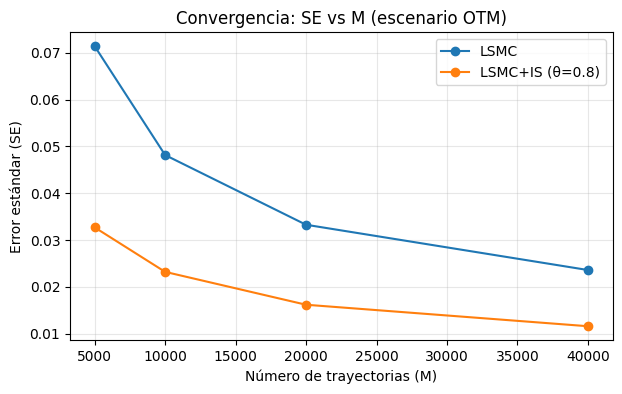

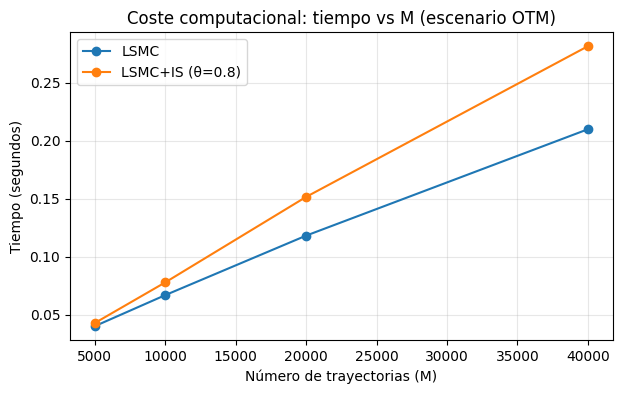

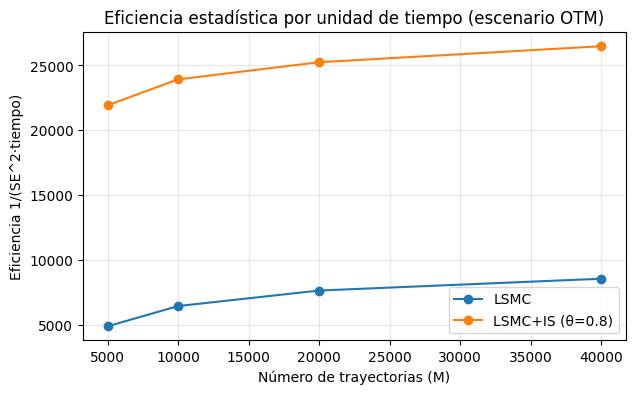

In [14]:
# Gráfico 1: SE vs M (escala log opcional)
plt.figure(figsize=(7,4))
for method, g in df_grid.groupby("method"):
    g = g.sort_values("M")
    plt.plot(g["M"], g["se"], marker="o", label=method)
plt.xlabel("Número de trayectorias (M)")
plt.ylabel("Error estándar (SE)")
plt.title("Convergencia: SE vs M (escenario OTM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Gráfico 2: Tiempo vs M
plt.figure(figsize=(7,4))
for method, g in df_grid.groupby("method"):
    g = g.sort_values("M")
    plt.plot(g["M"], g["seconds"], marker="o", label=method)
plt.xlabel("Número de trayectorias (M)")
plt.ylabel("Tiempo (segundos)")
plt.title("Coste computacional: tiempo vs M (escenario OTM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Gráfico 3: Eficiencia vs M
plt.figure(figsize=(7,4))
for method, g in df_grid.groupby("method"):
    g = g.sort_values("M")
    plt.plot(g["M"], g["eff"], marker="o", label=method)
plt.xlabel("Número de trayectorias (M)")
plt.ylabel("Eficiencia 1/(SE^2·tiempo)")
plt.title("Eficiencia estadística por unidad de tiempo (escenario OTM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 4.5 Tabla resumen “para tribunal” (una página)

Una tabla compacta con los resultados clave por escenario. Es lo que normalmente mejor funciona en defensa.

In [15]:
def compact(df):
    cols = ["method","price","se","ci_low","ci_high","seconds","eff","early_ex_prob","mean_ex_time","n_paths","n_steps"]
    return df[cols]

summary = pd.concat([
    compact(df_val.assign(scenario="Validación σ constante")),
    compact(df_rs.assign(scenario="Cambio de régimen (base)")),
    compact(df_otm.assign(scenario="OTM")),
], ignore_index=True)

summary

,method,price,se,ci_low,ci_high,seconds,eff,early_ex_prob,mean_ex_time,n_paths,n_steps
0,CRR (N=500),4.639128,NaN,NaN,NaN,0.013003,NaN,NaN,NaN,NaN,500
1,LSMC,4.584243,0.037494,4.510755,4.657730,0.149616,4754.522268,0.180133,0.959845,30000.0,50
2,LSMC,4.805492,0.040136,4.726825,4.884159,0.177719,3492.964574,0.167000,0.964505,30000.0,50
3,LSMC+IS (θ=0.8),4.826408,0.018868,4.789428,4.863389,0.252112,11142.153390,0.280967,0.921803,30000.0,50
4,LSMC,2.137547,0.028503,2.081681,2.193413,0.177443,6936.713582,0.067133,0.988968,30000.0,60
5,LSMC+IS (θ=0.8),2.096207,0.013285,2.070168,2.122246,0.231116,24514.943189,0.175900,0.960141,30000.0,60


## Exportación directa a LaTeX (para que texto y notebook “encajen”)

Si te llevas estas tablas a tu `main.tex`, evita copia/pega manual y mantiene coherencia cuando reajustes \(M\), \(N\) o \(\theta\).

- Genera `.tex` listos para `\input{}`.
- Genera `.csv` por si luego quieres graficar o revisar en Excel.

In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTDIR = "outputs_tfg"
os.makedirs(OUTDIR, exist_ok=True)

def _fmt(x, nd=4):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "---"
    return f"{x:.{nd}f}"

def _fmt_ci(lo, hi, nd=4):
    if lo is None or hi is None:
        return "---"
    if (isinstance(lo, float) and np.isnan(lo)) or (isinstance(hi, float) and np.isnan(hi)):
        return "---"
    return f"[{lo:.{nd}f}, {hi:.{nd}f}]"

def compact_table(df, scenario=None, keep_theta=False):
    """
    Devuelve una tabla compacta (para el capítulo) con:
    Método, Precio, SE, IC95, Tiempo(s), Eficiencia(×10^3)
    """
    d = df.copy()

    # Construimos columna IC en una sola celda para ahorrar ancho
    d["IC 95%"] = [
        _fmt_ci(lo, hi, 4) for lo, hi in zip(d.get("ci_low", [np.nan]*len(d)),
                                             d.get("ci_high", [np.nan]*len(d)))
    ]

    # Eficiencia en miles para que no ensanche la tabla
    if "eff" in d.columns:
        d["Eficiencia (×10^3)"] = d["eff"] / 1000.0
    else:
        d["Eficiencia (×10^3)"] = np.nan

    # Selección de columnas
    cols = ["method", "price", "se", "IC 95%", "seconds", "Eficiencia (×10^3)"]
    d = d[cols]

    # Renombrado a español
    d = d.rename(columns={
        "method": "Método",
        "price": "Precio",
        "se": "SE",
        "seconds": "Tiempo (s)",
    })

    # Formateo como strings (control total del ancho)
    d["Precio"] = d["Precio"].apply(lambda x: _fmt(x, 4))
    d["SE"] = d["SE"].apply(lambda x: _fmt(x, 4))
    d["Tiempo (s)"] = d["Tiempo (s)"].apply(lambda x: _fmt(x, 3))
    d["Eficiencia (×10^3)"] = d["Eficiencia (×10^3)"].apply(lambda x: _fmt(x, 2))

    # (Opcional) si quieres añadir escenario en la global
    if scenario is not None:
        d.insert(0, "Escenario", scenario)

    # Mejora visual: primer col. tipo párrafo para que “Método” no empuje el ancho
    return d

def save_latex_table(df_str, filename, colfmt):
    tex = df_str.to_latex(
        index=False,
        escape=False,
        column_format=colfmt,
        bold_rows=False,
        longtable=False
    )
    with open(os.path.join(OUTDIR, filename), "w", encoding="utf-8") as f:
        f.write(tex)

# -------------------------
# 1) Tablas compactas
# -------------------------

# Validación
tab_val = compact_table(df_val, scenario=None)
save_latex_table(tab_val, "tabla_validacion.tex", colfmt="p{3.3cm}rrrrr")

# Régimen switching
tab_rs = compact_table(df_rs, scenario=None)
save_latex_table(tab_rs, "tabla_regimen.tex", colfmt="p{3.3cm}rrrrr")

# OTM
tab_otm = compact_table(df_otm, scenario=None)
save_latex_table(tab_otm, "tabla_otm.tex", colfmt="p{3.3cm}rrrrr")

# Theta (OTM) — aquí interesa mostrar theta en el “Método”
tab_theta = compact_table(df_theta, scenario=None)
save_latex_table(tab_theta, "tabla_theta_otm.tex", colfmt="p{3.3cm}rrrrr")

# Convergencia (OTM) usando df_grid: solo las columnas clave
dg = df_grid.copy()
dg["IC 95%"] = "---"   # no lo estás guardando en df_grid; lo omitimos para no ensanchar
dg["Eficiencia (×10^3)"] = dg["eff"]/1000.0

dg = dg.rename(columns={"method":"Método", "M":"M", "price":"Precio", "se":"SE", "seconds":"Tiempo (s)"})
dg = dg[["Método","M","Precio","SE","Tiempo (s)","Eficiencia (×10^3)"]].copy()

dg["Precio"] = dg["Precio"].apply(lambda x: _fmt(x, 4))
dg["SE"] = dg["SE"].apply(lambda x: _fmt(x, 4))
dg["Tiempo (s)"] = dg["Tiempo (s)"].apply(lambda x: _fmt(x, 3))
dg["Eficiencia (×10^3)"] = dg["Eficiencia (×10^3)"].apply(lambda x: _fmt(x, 2))

save_latex_table(dg, "tabla_convergencia_otm.tex", colfmt="p{3.3cm}rrrrr")

# Resumen global (con escenario, compacta)
summary_global = pd.concat([
    compact_table(df_val, scenario="Validación σ constante"),
    compact_table(df_rs, scenario="Cambio de régimen (base)"),
    compact_table(df_otm, scenario="OTM"),
], ignore_index=True)

save_latex_table(summary_global, "tabla_resumen_global.tex", colfmt="p{3.2cm}p{3.2cm}rrrrr")

# -------------------------
# 2) Figuras (desde df_grid)
# -------------------------
def plot_from_grid(df, y, ylabel, title, fname):
    plt.figure()
    for meth, g in df.groupby("method"):
        g = g.sort_values("M")
        plt.plot(g["M"], g[y], marker="o", label=meth)
    plt.xlabel("Número de trayectorias (M)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTDIR, fname), dpi=200)
    plt.close()

plot_from_grid(df_grid, "se", "Error estándar (SE)", "Convergencia: SE vs M (escenario OTM)", "convergencia_se_vs_m_otm.png")
plot_from_grid(df_grid, "seconds", "Tiempo (segundos)", "Coste computacional: tiempo vs M (escenario OTM)", "coste_tiempo_vs_m_otm.png")
plot_from_grid(df_grid, "eff", "Eficiencia 1/(SE^2·tiempo)", "Eficiencia estadística por unidad de tiempo (escenario OTM)", "eficiencia_vs_m_otm.png")

print("Export OK ->", OUTDIR)


Export OK -> outputs_tfg


In [20]:
# ==========================================
# Sensibilidad económica (OTM): r-grid y q-grid
# Exporta tablas LaTeX para el capítulo 4
# ==========================================

# Requiere que existan ya en el notebook:
# - scenario_otm (dict), regime_rs (RegimeParams), market (MarketParams)
# - run_lsmc_standard, run_lsmc_is
# - OUTDIR, save_latex_table, _fmt_ci (o compact_table si quieres reutilizar)
# - pandas as pd, numpy as np

theta_sens = 0.8  # coherente con tu análisis de convergencia (OTM)

# Guardamos el market original para restaurar al final
market_base = market

def _sens_table(rows, param_name, colfmt):
    """
    rows: list[dict] con claves:
      param_value, method, price, se, ci_low, ci_high, seconds, eff
    param_name: 'r' o 'q' (solo para nombre de columna)
    """
    df = pd.DataFrame(rows).copy()

    # IC compacto en una celda
    df["IC 95%"] = [_fmt_ci(lo, hi, 4) for lo, hi in zip(df["ci_low"], df["ci_high"])]

    # Eficiencia en miles para que no ensanche
    df["Eficiencia (×10^3)"] = df["eff"] / 1000.0

    # Redondeos estéticos (no toques el cálculo, solo presentación)
    df["Precio"] = df["price"].map(lambda x: float(x))
    df["SE"] = df["se"].map(lambda x: float(x))
    df["Tiempo (s)"] = df["seconds"].map(lambda x: float(x))

    # Columna del parámetro
    df[param_name] = df["param_value"].map(lambda x: float(x))

    # Selección y orden de columnas
    df_out = df[[param_name, "method", "Precio", "SE", "IC 95%", "Tiempo (s)", "Eficiencia (×10^3)"]].copy()
    df_out = df_out.rename(columns={"method": "Método"})

    # Formato: fijamos 2 decimales para r/q y 4 para precio/SE
    df_out[param_name] = df_out[param_name].map(lambda x: f"{x:.2f}")
    df_out["Precio"] = df_out["Precio"].map(lambda x: f"{x:.4f}")
    df_out["SE"] = df_out["SE"].map(lambda x: f"{x:.4f}")
    df_out["Tiempo (s)"] = df_out["Tiempo (s)"].map(lambda x: f"{x:.3f}")
    df_out["Eficiencia (×10^3)"] = df_out["Eficiencia (×10^3)"].map(lambda x: f"{x:.2f}")

    save_latex_table(df_out, f"tabla_sens_{param_name}_otm.tex", colfmt=colfmt)
    return df_out


# -------------------------
# (A) Sensibilidad a r (OTM)
# -------------------------
r_grid = [0.00, 0.02, 0.05, 0.08]
rows_r = []

for r_val in r_grid:
    market = MarketParams(r=float(r_val), q=market_base.q)

    # LSMC
    res_lsmc = run_lsmc_standard(
        scenario_otm["S0"], scenario_otm["K"], scenario_otm["T"],
        scenario_otm["n_steps"], scenario_otm["n_paths"],
        regime_rs, market,
        x0=0, seed=scenario_otm["seed"],
        basis="laguerre", degree=2, min_itm=50
    )
    rows_r.append({
        "param_value": r_val, "method": "LSMC",
        "price": res_lsmc["price"], "se": res_lsmc["se"],
        "ci_low": res_lsmc["ci_low"], "ci_high": res_lsmc["ci_high"],
        "seconds": res_lsmc["seconds"], "eff": res_lsmc["eff"]
    })

    # LSMC + IS
    res_is = run_lsmc_is(
        scenario_otm["S0"], scenario_otm["K"], scenario_otm["T"],
        scenario_otm["n_steps"], scenario_otm["n_paths"],
        regime_rs, market,
        theta=float(theta_sens),
        x0=0, seed=scenario_otm["seed"],
        basis="laguerre", degree=2, min_itm=50
    )
    rows_r.append({
        "param_value": r_val, "method": f"LSMC+IS ($\\theta={theta_sens}$)",
        "price": res_is["price"], "se": res_is["se"],
        "ci_low": res_is["ci_low"], "ci_high": res_is["ci_high"],
        "seconds": res_is["seconds"], "eff": res_is["eff"]
    })

# Exportamos .tex (colfmt ajustado: parámetro + método + 5 cols numéricas)
tab_r_otm = _sens_table(rows_r, param_name="r", colfmt="r p{3.6cm} r r r r r")

# -------------------------
# (B) Sensibilidad a q (OTM)
# -------------------------
q_grid = [0.00, 0.02, 0.04]
rows_q = []

for q_val in q_grid:
    market = MarketParams(r=market_base.r, q=float(q_val))

    # LSMC
    res_lsmc = run_lsmc_standard(
        scenario_otm["S0"], scenario_otm["K"], scenario_otm["T"],
        scenario_otm["n_steps"], scenario_otm["n_paths"],
        regime_rs, market,
        x0=0, seed=scenario_otm["seed"],
        basis="laguerre", degree=2, min_itm=50
    )
    rows_q.append({
        "param_value": q_val, "method": "LSMC",
        "price": res_lsmc["price"], "se": res_lsmc["se"],
        "ci_low": res_lsmc["ci_low"], "ci_high": res_lsmc["ci_high"],
        "seconds": res_lsmc["seconds"], "eff": res_lsmc["eff"]
    })

    # LSMC + IS
    res_is = run_lsmc_is(
        scenario_otm["S0"], scenario_otm["K"], scenario_otm["T"],
        scenario_otm["n_steps"], scenario_otm["n_paths"],
        regime_rs, market,
        theta=float(theta_sens),
        x0=0, seed=scenario_otm["seed"],
        basis="laguerre", degree=2, min_itm=50
    )
    rows_q.append({
        "param_value": q_val, "method": f"LSMC+IS ($\\theta={theta_sens}$)",
        "price": res_is["price"], "se": res_is["se"],
        "ci_low": res_is["ci_low"], "ci_high": res_is["ci_high"],
        "seconds": res_is["seconds"], "eff": res_is["eff"]
    })

tab_q_otm = _sens_table(rows_q, param_name="q", colfmt="r p{3.6cm} r r r r r")

# Restauramos el market original
market = market_base

print("Tablas exportadas:")
print(" -", os.path.join(OUTDIR, "tabla_sens_r_otm.tex"))
print(" -", os.path.join(OUTDIR, "tabla_sens_q_otm.tex"))


Tablas exportadas:
 - outputs_tfg\tabla_sens_r_otm.tex
 - outputs_tfg\tabla_sens_q_otm.tex
